# Bài thực hành Ngày 1: Đọc prediction YOLO11 để hiểu định dạng nhãn

## Mục tiêu học tập
Bạn sẽ quan sát các **prediction** (dự đoán) của YOLO11 và suy ra **định dạng ground truth** mà người gán nhãn cần tạo. Prediction **không** phải nhãn chuẩn; model score **không** phải điểm chất lượng của nhãn.

> **Lab hôm nay (quan sát):** ảnh công khai → checkpoint → prediction → đối chiếu guideline → hiểu định dạng ground truth.
>
> **Vòng đời production (để nhớ khi viết báo cáo):** ảnh thô → guideline → ground truth → huấn luyện → prediction → QC/rework.

## Thuật ngữ ngắn
- **Taxonomy:** danh sách lớp cố định đi kèm dữ liệu/checkpoint.
- **Checkpoint:** tệp model `.pt` đã huấn luyện sẵn.
- **Guideline:** quy tắc gán nhãn do người viết.
- **Annotator / Reviewer:** người gán nhãn / người kiểm tra chất lượng.
- **Escalation:** ca khó → hỏi Lab Coach, không tự bịa nhãn.


## Quy tắc bài lab

- Không huấn luyện hoặc tinh chỉnh mô hình trong bài này. Không tự đổi checkpoint, threshold hoặc mã nguồn trừ khi GV cho phép (nếu đổi phải ghi trong `REPORT.md`).
- Xem cả hình minh họa và tệp JSON; dùng lỗi, vật thể bị bỏ sót và trường hợp khó quyết định nhãn làm bằng chứng.
- GPU giúp chạy nhanh hơn; CPU vẫn chạy được.
- Ngày 1 không dùng CVAT; chỉ dùng ba ảnh COCO công khai có sẵn — không tải ảnh cá nhân hay dữ liệu nội bộ.
- **Bài nộp = repository GitHub** (thư mục `report/`). Chỉ nộp **link repo** trên LMS.
- Notebook **không** tự tạo `REPORT.md`. Bạn tải mẫu `reports/REPORT_TEMPLATE.md` từ repo, điền, rồi **upload** vào Colab Files.

## Trước khi chạy ô setup
1. Đã tạo repo từ template và nhấn **Copy to Drive** trên Colab.
2. Chạy **Run all** từ đầu; nếu vừa đổi package, `Runtime → Restart session` rồi Run all lại.
3. Ô setup **xóa** thư mục `day1_lab_outputs/` cũ — đừng chạy lại ô setup giữa chừng nếu đã có evidence.


In [1]:
# Ghim phiên bản đã dùng để xây dựng và smoke-test notebook.
%pip -q install ultralytics==8.4.145

import hashlib
import json
import platform
import re
import shutil
from pathlib import Path
from urllib.error import HTTPError, URLError
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
from PIL import Image
import torch
import ultralytics
from ultralytics import YOLO

ULTRALYTICS_VERSION_PIN = "8.4.145"
CLASSIFICATION_MODEL_FILE = "yolo11n-cls.pt"
DETECTION_MODEL_FILE = "yolo11n.pt"
SEGMENTATION_MODEL_FILE = "yolo11n-seg.pt"
MODEL_ASSETS = {
    "yolo11n-cls.pt": {
        "url": "https://github.com/ultralytics/assets/releases/download/v8.4.0/yolo11n-cls.pt",
        "sha256": "c62d41bf9625777760018bf914d2e6cd472420ccd01706d97a61cb6c82502bd7",
    },
    "yolo11n.pt": {
        "url": "https://github.com/ultralytics/assets/releases/download/v8.4.0/yolo11n.pt",
        "sha256": "0ebbc80d4a7680d14987a577cd21342b65ecfd94632bd9a8da63ae6417644ee1",
    },
    "yolo11n-seg.pt": {
        "url": "https://github.com/ultralytics/assets/releases/download/v8.4.0/yolo11n-seg.pt",
        "sha256": "55ed65c56c91713d23e8402371c6c49a6fd84f257f7dce452e8d70e41dcbe152",
    },
}
REPORT_TEMPLATE_ASSET = {
    "url": "https://raw.githubusercontent.com/VinUni-AI20k/K5-L2-Day1-Data-Overview-AI-ML-DL-Student/main/reports/REPORT_TEMPLATE.md",
    "sha256": "2f67dccc52f060feb38b11a9e5d4880016f3b218f8cb2cb63982d7c52bb7d029",
}
DEVICE = 0 if torch.cuda.is_available() else "cpu"
OUTPUT_DIR = Path("day1_lab_outputs")
VISUAL_DIR = OUTPUT_DIR / "visuals"
IMAGE_DIR = Path("day1_lab_images")
REPORT_PATH = Path("REPORT.md")
if OUTPUT_DIR.exists():
    shutil.rmtree(OUTPUT_DIR)
for directory in (VISUAL_DIR, IMAGE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

def download_with_sha256(label, url, target, expected_sha256):
    target = Path(target)
    if target.exists() and sha256_file(target) != expected_sha256:
        target.unlink()
    if not target.exists():
        temporary_target = target.with_name(f".{target.name}.download")
        temporary_target.unlink(missing_ok=True)
        try:
            urlretrieve(url, temporary_target)
        except (HTTPError, URLError) as error:
            temporary_target.unlink(missing_ok=True)
            raise RuntimeError(f"Không tải được {label}; chạy lại một lần rồi báo mentor.") from error
        actual_sha256 = sha256_file(temporary_target)
        if actual_sha256 != expected_sha256:
            temporary_target.unlink(missing_ok=True)
            raise RuntimeError(
                f"Checksum sai cho {label}: expected={expected_sha256}, actual={actual_sha256}. "
                "Không load tệp này; hãy báo mentor."
            )
        temporary_target.replace(target)
    actual_sha256 = sha256_file(target)
    return target, actual_sha256

# REPORT.md không tự tạo. Học viên điền trên máy rồi dùng ô Upload trong notebook.
print("Nhắc: làm REPORT.md từ reports/REPORT_TEMPLATE.md trên máy, rồi chạy ô Upload REPORT.md.")

MODEL_SHA256 = {}
for model_file, metadata in MODEL_ASSETS.items():
    _, actual_sha256 = download_with_sha256(
        f"model {model_file}", metadata["url"], model_file, metadata["sha256"]
    )
    MODEL_SHA256[model_file] = actual_sha256
    print(f"PASS model={model_file} sha256={actual_sha256[:12]}…")

print(f"Python: {platform.python_version()}")
print(f"PyTorch: {torch.__version__}")
print(f"Ultralytics: {ultralytics.__version__}")
print(f"Device: {'cuda' if torch.cuda.is_available() else 'cpu'}")
assert ultralytics.__version__ == ULTRALYTICS_VERSION_PIN, (
    f"Sai phiên bản Ultralytics: {ultralytics.__version__}; cần {ULTRALYTICS_VERSION_PIN}. "
    "Hãy restart runtime và chạy lại từ ô đầu."
)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart#ultralytics-settings.
Nhắc: làm REPORT.md từ reports/REPORT_TEMPLATE.md trên máy, rồi chạy ô Upload REPORT.md.
PASS model=yolo11n-cls.pt sha256=c62d41bf9625…
PASS model=yolo11n.pt sha256=0ebbc80d4a76…
PASS model=yolo11n-seg.pt sha256=55ed65c56c91…
Python: 3.13.16
PyTorch: 2.11.0+cu130
Ultralytics: 8.4.145
Device: cuda


PASS sample=traffic coco_id=210273 sha256=3ec23de63592…
PASS sample=kitchen coco_id=397133 sha256=09e1d25c75f7…
PASS sample=dining coco_id=166918 sha256=a7f8457580a2…


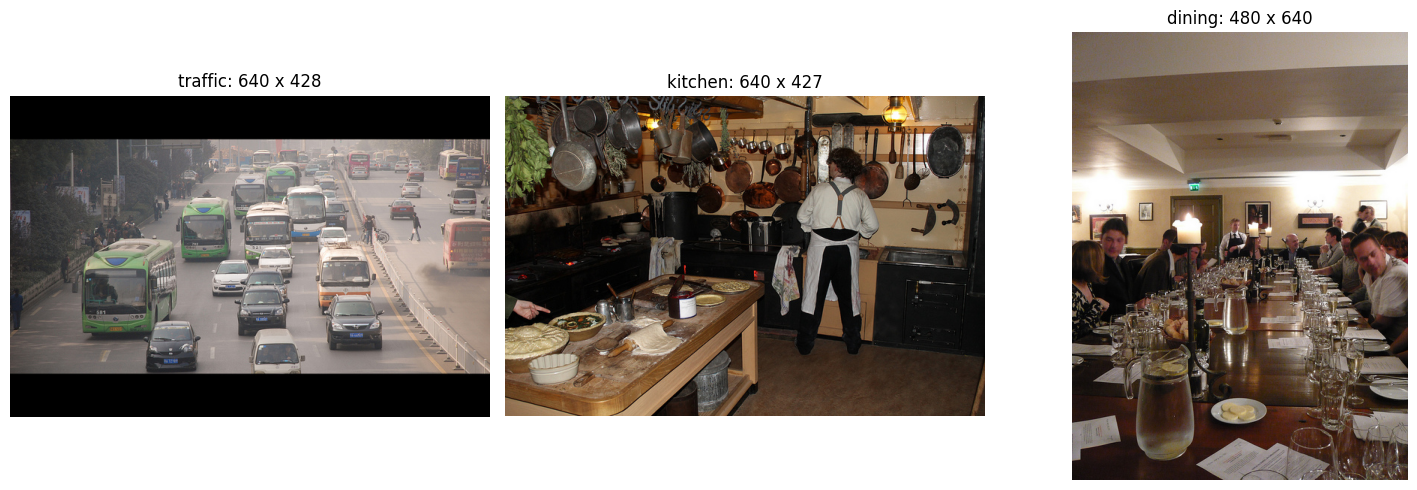

In [2]:
# Ảnh COCO công khai, cố định bằng image ID và SHA-256.
# Host ảnh COCO hiện phục vụ các tệp này qua HTTP; checksum bên dưới kiểm tra tính toàn vẹn.
SAMPLES = {
    "traffic": {
        "coco_image_id": 210273,
        "url": "http://images.cocodataset.org/val2017/000000210273.jpg",
        "sha256": "3ec23de63592c1eef86740fd46fed2cb66170fca02b695d37e6ae379dcee4355",
        "source_title": "Wuhan", "source_creator": "Tauno Tõhk (toehk)",
        "source_url": "https://www.flickr.com/photo.gne?id=5336041838",
        "license_name": "CC BY 2.0", "license_url": "https://creativecommons.org/licenses/by/2.0/",
    },
    "kitchen": {
        "coco_image_id": 397133,
        "url": "http://images.cocodataset.org/val2017/000000397133.jpg",
        "sha256": "09e1d25c75f7879bdaa69c327fece5cabacd53939c8c2ef9e87f1c97a2e478c4",
        "source_title": "Kitchen", "source_creator": "Maggie Stephens (Pot Noodle)",
        "source_url": "https://www.flickr.com/photo.gne?id=6255196340",
        "license_name": "CC BY 2.0", "license_url": "https://creativecommons.org/licenses/by/2.0/",
    },
    "dining": {
        "coco_image_id": 166918,
        "url": "http://images.cocodataset.org/val2017/000000166918.jpg",
        "sha256": "a7f8457580a2bb8635ca7acd1b2061ea7977a84418e5e8441a77ba1f861d7e22",
        "source_title": "Big Wine Thing", "source_creator": "WordRidden",
        "source_url": "https://www.flickr.com/photo.gne?id=4745624149",
        "license_name": "CC BY 2.0", "license_url": "https://creativecommons.org/licenses/by/2.0/",
    },
}
for sample_id, metadata in SAMPLES.items():
    target = IMAGE_DIR / f"{sample_id}.jpg"
    _, actual_sha256 = download_with_sha256(
        f"sample {sample_id}", metadata["url"], target, metadata["sha256"]
    )
    print(f"PASS sample={sample_id} coco_id={metadata['coco_image_id']} sha256={actual_sha256[:12]}…")
attribution_lines = [
    "# Image attribution", "",
    "Source images were downloaded from COCO 2017 validation. Generated PNG evidence adds model predictions/charts; these are modified versions.",
    "", "| Sample | Original work / creator | Source | License | Change |",
    "| --- | --- | --- | --- | --- |",
]
for sample_id, metadata in SAMPLES.items():
    attribution_lines.append(
        f"| `{sample_id}` (COCO {metadata['coco_image_id']}) | {metadata['source_title']} / {metadata['source_creator']} | "
        f"[Flickr]({metadata['source_url']}) | [{metadata['license_name']}]({metadata['license_url']}) | "
        "Model prediction/chart overlay in generated PNG evidence |"
    )
(OUTPUT_DIR / "IMAGE_ATTRIBUTION.md").write_text("\n".join(attribution_lines) + "\n", encoding="utf-8")
images = {sample_id: Image.open(IMAGE_DIR / f"{sample_id}.jpg").convert("RGB") for sample_id in SAMPLES}
fig, axes = plt.subplots(1, len(images), figsize=(15, 5))
for ax, (sample_id, image) in zip(axes, images.items()):
    ax.imshow(image); ax.set_title(f"{sample_id}: {image.width} x {image.height}"); ax.axis("off")
plt.tight_layout(); plt.show()


## 1. Phân loại ảnh – một lớp cho toàn bộ ảnh

Checkpoint `yolo11n-cls.pt` xếp hạng các lớp **ImageNet-1K** cho **toàn bộ ảnh** (không phải từng object). `rank=1` là prediction có model score cao nhất.

**Lưu ý:** Ảnh mẫu là cảnh COCO (vd. `traffic`), còn taxonomy là ImageNet — top-1 có thể trông “lạ”. Đó là tư liệu học, không phải lỗi máy.

**Ví dụ đọc field (số minh họa):** `class_id=919`, `class_name=streetcar`, `rank=1`, `score=0.41`, `taxonomy_name=ImageNet-1K` → “một lớp cho cả ảnh”.

**Sau khi chạy:** mở `day1_lab_outputs/classification_predictions.json`, lọc `sample_id=traffic`, `rank=1`. Trả lời mục **1** trong `REPORT.md`.


In [3]:
classification_model = YOLO(CLASSIFICATION_MODEL_FILE)
classification_model_sha256 = MODEL_SHA256[CLASSIFICATION_MODEL_FILE]
classification_records = []
for sample_id, image in images.items():
    result = classification_model.predict(source=image, device=DEVICE, verbose=False)[0]
    probs = result.probs
    top_ids = probs.top5
    top_scores = probs.top5conf.tolist()
    names = result.names
    for rank, (class_id, score) in enumerate(zip(top_ids, top_scores), start=1):
        classification_records.append({
            "sample_id": sample_id, "coco_image_id": SAMPLES[sample_id]["coco_image_id"],
            "image_width": image.width, "image_height": image.height,
            "task": "image_classification", "taxonomy_name": "ImageNet-1K",
            "model_file": CLASSIFICATION_MODEL_FILE, "model_sha256": classification_model_sha256,
            "ultralytics_version": ultralytics.__version__, "rank": rank,
            "class_id": int(class_id), "class_name": names[int(class_id)],
            "score": round(float(score), 6),
        })
with open(OUTPUT_DIR / "classification_predictions.json", "w", encoding="utf-8") as file:
    json.dump(classification_records, file, indent=2, ensure_ascii=False)
print(json.dumps(classification_records[:5], indent=2, ensure_ascii=False))


[
  {
    "sample_id": "traffic",
    "coco_image_id": 210273,
    "image_width": 640,
    "image_height": 428,
    "task": "image_classification",
    "taxonomy_name": "ImageNet-1K",
    "model_file": "yolo11n-cls.pt",
    "model_sha256": "c62d41bf9625777760018bf914d2e6cd472420ccd01706d97a61cb6c82502bd7",
    "ultralytics_version": "8.4.145",
    "rank": 1,
    "class_id": 468,
    "class_name": "cab",
    "score": 0.510915
  },
  {
    "sample_id": "traffic",
    "coco_image_id": 210273,
    "image_width": 640,
    "image_height": 428,
    "task": "image_classification",
    "taxonomy_name": "ImageNet-1K",
    "model_file": "yolo11n-cls.pt",
    "model_sha256": "c62d41bf9625777760018bf914d2e6cd472420ccd01706d97a61cb6c82502bd7",
    "ultralytics_version": "8.4.145",
    "rank": 2,
    "class_id": 654,
    "class_name": "minibus",
    "score": 0.164284
  },
  {
    "sample_id": "traffic",
    "coco_image_id": 210273,
    "image_width": 640,
    "image_height": 428,
    "task": "image_c

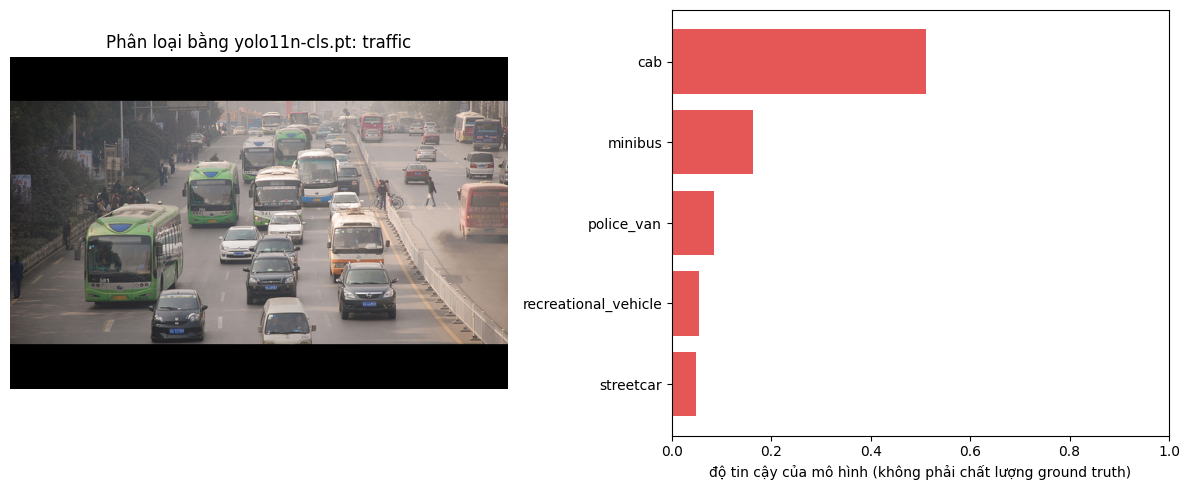

In [4]:
sample_id = "traffic"
rows = [row for row in classification_records if row["sample_id"] == sample_id]
fig, (image_ax, chart_ax) = plt.subplots(1, 2, figsize=(12, 5))
image_ax.imshow(images[sample_id]); image_ax.axis("off"); image_ax.set_title(f"Phân loại bằng {CLASSIFICATION_MODEL_FILE}: {sample_id}")
chart_ax.barh([r["class_name"] for r in rows][::-1], [r["score"] for r in rows][::-1], color="#e45756")
chart_ax.set_xlim(0, 1); chart_ax.set_xlabel("độ tin cậy của mô hình (không phải chất lượng ground truth)")
plt.tight_layout(); plt.savefig(VISUAL_DIR / "classification_top5.png", dpi=160, bbox_inches="tight"); plt.show()
del classification_model
if torch.cuda.is_available(): torch.cuda.empty_cache()


## 2. Phát hiện vật thể – một hộp cho mỗi vật thể

Checkpoint `yolo11n.pt` dùng taxonomy **COCO-80**. Mỗi prediction có lớp, model score và hộp `bbox_xyxy = [x_min, y_min, x_max, y_max]` theo **pixel**, gốc `(0, 0)` ở góc trên-trái.

**Ví dụ đọc field (số minh họa):** `bbox_xyxy=[40.2, 80.0, 200.5, 300.1]` → từ góc trên-trái `(40.2, 80.0)` đến góc dưới-phải `(200.5, 300.1)`.

Ngưỡng (`conf`) **lọc prediction**, không phải quy tắc bỏ object khi tạo ground truth. JSON bài lab dùng ngưỡng `0.35`; ô sau so sánh thêm `0.20` và `0.60`.

**Sau khi chạy:** mở `detection_predictions.json` + `visuals/detection_predictions.png`, sample `kitchen`. Trả lời mục **2** trong `REPORT.md` (gồm so threshold và quy tắc box / escalation).


In [5]:
detection_model = YOLO(DETECTION_MODEL_FILE)
detection_model_sha256 = MODEL_SHA256[DETECTION_MODEL_FILE]
DETECTION_SCORE_THRESHOLD = 0.35
def run_detection(sample_id, image, threshold):
    result = detection_model.predict(source=image, conf=threshold, device=DEVICE, verbose=False)[0]
    records = []
    if result.boxes is None: return records
    for box, cls, conf in zip(result.boxes.xyxy.cpu().tolist(), result.boxes.cls.cpu().tolist(), result.boxes.conf.cpu().tolist()):
        x_min_raw, y_min_raw, x_max_raw, y_max_raw = [float(v) for v in box]
        x_min, y_min, x_max, y_max = [round(v, 2) for v in (x_min_raw, y_min_raw, x_max_raw, y_max_raw)]
        class_id = int(cls)
        records.append({"sample_id": sample_id, "coco_image_id": SAMPLES[sample_id]["coco_image_id"],
                        "image_width": image.width, "image_height": image.height,
                        "task": "object_detection", "taxonomy_name": "COCO-80",
                        "model_file": DETECTION_MODEL_FILE, "model_sha256": detection_model_sha256,
                        "ultralytics_version": ultralytics.__version__, "score_threshold": threshold,
                        "class_id": class_id, "class_name": result.names[class_id], "score": round(float(conf), 6),
                        "coordinate_unit": "pixel", "bbox_format": "xyxy",
                        "bbox_xyxy": [x_min, y_min, x_max, y_max],
                        "bbox_width": round(x_max_raw-x_min_raw, 2), "bbox_height": round(y_max_raw-y_min_raw, 2)})
    return records
detection_records = []
for sample_id, image in images.items():
    detection_records.extend(run_detection(sample_id, image, DETECTION_SCORE_THRESHOLD))
with open(OUTPUT_DIR / "detection_predictions.json", "w", encoding="utf-8") as file:
    json.dump(detection_records, file, indent=2, ensure_ascii=False)
print(f"Ngưỡng {DETECTION_MODEL_FILE}: {DETECTION_SCORE_THRESHOLD}; số vật thể phát hiện: {len(detection_records)}")
print(json.dumps(detection_records[:8], indent=2, ensure_ascii=False))


Ngưỡng yolo11n.pt: 0.35; số vật thể phát hiện: 53
[
  {
    "sample_id": "traffic",
    "coco_image_id": 210273,
    "image_width": 640,
    "image_height": 428,
    "task": "object_detection",
    "taxonomy_name": "COCO-80",
    "model_file": "yolo11n.pt",
    "model_sha256": "0ebbc80d4a7680d14987a577cd21342b65ecfd94632bd9a8da63ae6417644ee1",
    "ultralytics_version": "8.4.145",
    "score_threshold": 0.35,
    "class_id": 5,
    "class_name": "bus",
    "score": 0.912558,
    "coordinate_unit": "pixel",
    "bbox_format": "xyxy",
    "bbox_xyxy": [
      93.17,
      187.95,
      223.01,
      320.91
    ],
    "bbox_width": 129.84,
    "bbox_height": 132.96
  },
  {
    "sample_id": "traffic",
    "coco_image_id": 210273,
    "image_width": 640,
    "image_height": 428,
    "task": "object_detection",
    "taxonomy_name": "COCO-80",
    "model_file": "yolo11n.pt",
    "model_sha256": "0ebbc80d4a7680d14987a577cd21342b65ecfd94632bd9a8da63ae6417644ee1",
    "ultralytics_version": "8.

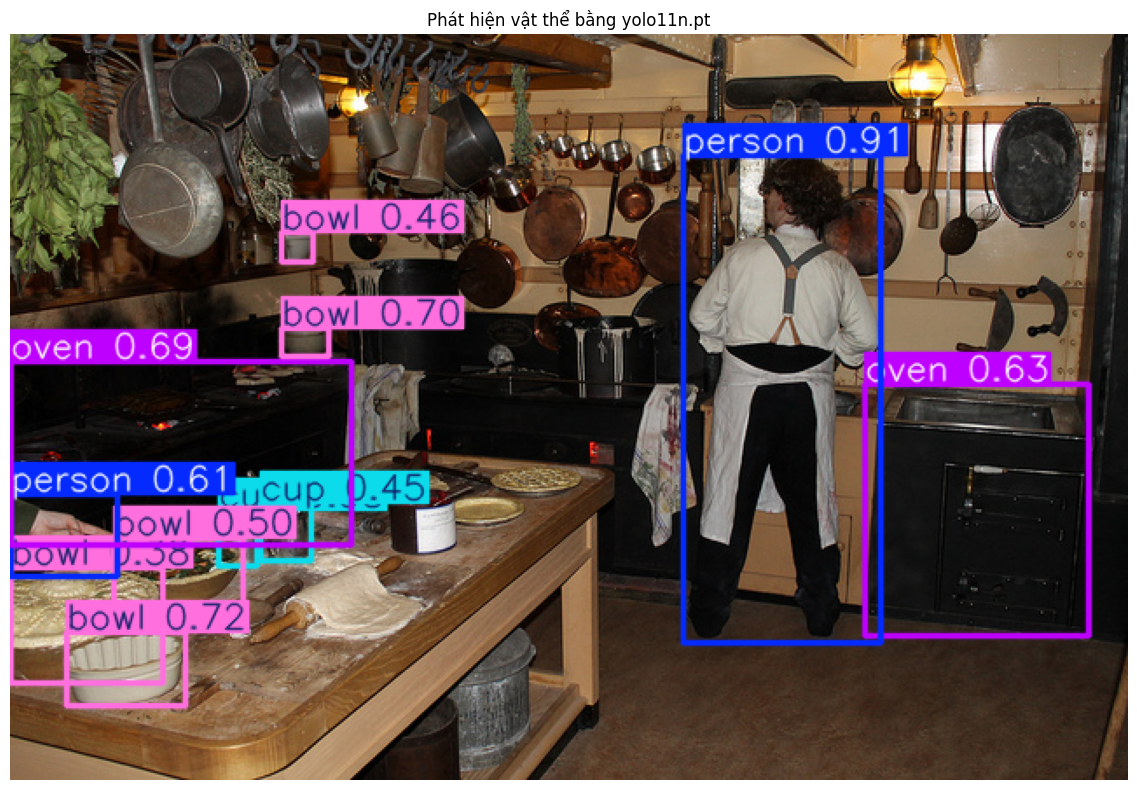

threshold=0.20: 17 vật thể → ['person', 'bowl', 'bowl', 'oven', 'oven', 'person', 'bowl', 'bowl', 'cup', 'cup', 'bowl', 'spoon', 'potted plant', 'spoon', 'dining table', 'spoon', 'bottle']
threshold=0.35: 11 vật thể → ['person', 'bowl', 'bowl', 'oven', 'oven', 'person', 'bowl', 'bowl', 'cup', 'cup', 'bowl']
threshold=0.60: 6 vật thể → ['person', 'bowl', 'bowl', 'oven', 'oven', 'person']


In [6]:
sample_id = "kitchen"
result = detection_model.predict(source=images[sample_id], conf=DETECTION_SCORE_THRESHOLD, device=DEVICE, verbose=False)[0]
annotated = result.plot()[:, :, ::-1]
plt.figure(figsize=(12, 8)); plt.imshow(annotated); plt.axis("off"); plt.title(f"Phát hiện vật thể bằng {DETECTION_MODEL_FILE}"); plt.tight_layout()
plt.savefig(VISUAL_DIR / "detection_predictions.png", dpi=160, bbox_inches="tight"); plt.show()
for threshold in (0.20, 0.35, 0.60):
    rows = run_detection(sample_id, images[sample_id], threshold)
    print(f"threshold={threshold:.2f}: {len(rows)} vật thể → {[row['class_name'] for row in rows]}")
del detection_model
if torch.cuda.is_available(): torch.cuda.empty_cache()


## 3. Phân đoạn theo từng đối tượng – một đa giác cho mỗi instance

Checkpoint `yolo11n-seg.pt` dùng COCO-80 và tạo **polygon** cho từng vật thể. Hai object cùng lớp vẫn có `instance_id` và đa giác riêng. Đây là **instance segmentation**, khác semantic segmentation (các pixel cùng lớp chung một mã).

`instance_id` có dạng `kitchen-001`: chỉ là ID trong output lab — **không** phải class ID hay tracking ID.

**Ví dụ:** box chỉ là hình chữ nhật; `polygon_xy` là các điểm `[x, y]` bám biên object.

**Sau khi chạy:** mở `segmentation_predictions.json` + `visuals/segmentation_prediction.png`, sample `kitchen`. Trả lời mục **3** trong `REPORT.md`.


In [7]:
segmentation_model = YOLO(SEGMENTATION_MODEL_FILE)
segmentation_model_sha256 = MODEL_SHA256[SEGMENTATION_MODEL_FILE]
SEGMENTATION_SCORE_THRESHOLD = 0.35
segmentation_records = []
for sample_id, image in images.items():
    result = segmentation_model.predict(source=image, conf=SEGMENTATION_SCORE_THRESHOLD, device=DEVICE, verbose=False)[0]
    if result.boxes is None or result.masks is None: continue
    polygons = result.masks.xy
    for index, (box, cls, conf, polygon) in enumerate(zip(result.boxes.xyxy.cpu().tolist(), result.boxes.cls.cpu().tolist(), result.boxes.conf.cpu().tolist(), polygons)):
        x_min, y_min, x_max, y_max = [round(float(v), 2) for v in box]
        class_id = int(cls)
        polygon_xy = [[round(float(x), 2), round(float(y), 2)] for x, y in polygon]
        segmentation_records.append({"sample_id": sample_id, "coco_image_id": SAMPLES[sample_id]["coco_image_id"],
            "image_width": image.width, "image_height": image.height,
            "task": "instance_segmentation", "taxonomy_name": "COCO-80",
            "model_file": SEGMENTATION_MODEL_FILE, "model_sha256": segmentation_model_sha256,
            "ultralytics_version": ultralytics.__version__, "score_threshold": SEGMENTATION_SCORE_THRESHOLD,
            "instance_id": f"{sample_id}-{index + 1:03d}",
            "class_id": class_id, "class_name": result.names[class_id], "score": round(float(conf), 6),
            "coordinate_unit": "pixel", "bbox_format": "xyxy",
            "bbox_xyxy": [x_min, y_min, x_max, y_max],
            "polygon_point_count": len(polygon_xy), "polygon_xy": polygon_xy})
with open(OUTPUT_DIR / "segmentation_predictions.json", "w", encoding="utf-8") as file:
    json.dump(segmentation_records, file, indent=2, ensure_ascii=False)
print(f"Số đối tượng {SEGMENTATION_MODEL_FILE}: {len(segmentation_records)}")
print(json.dumps(segmentation_records[:2], indent=2, ensure_ascii=False))


Số đối tượng yolo11n-seg.pt: 49
[
  {
    "sample_id": "traffic",
    "coco_image_id": 210273,
    "image_width": 640,
    "image_height": 428,
    "task": "instance_segmentation",
    "taxonomy_name": "COCO-80",
    "model_file": "yolo11n-seg.pt",
    "model_sha256": "55ed65c56c91713d23e8402371c6c49a6fd84f257f7dce452e8d70e41dcbe152",
    "ultralytics_version": "8.4.145",
    "score_threshold": 0.35,
    "instance_id": "traffic-001",
    "class_id": 5,
    "class_name": "bus",
    "score": 0.925745,
    "coordinate_unit": "pixel",
    "bbox_format": "xyxy",
    "bbox_xyxy": [
      95.3,
      188.72,
      224.08,
      319.96
    ],
    "polygon_point_count": 120,
    "polygon_xy": [
      [
        148.0,
        189.0
      ],
      [
        147.0,
        190.0
      ],
      [
        145.0,
        190.0
      ],
      [
        143.0,
        192.0
      ],
      [
        142.0,
        192.0
      ],
      [
        141.0,
        193.0
      ],
      [
        139.0,
      

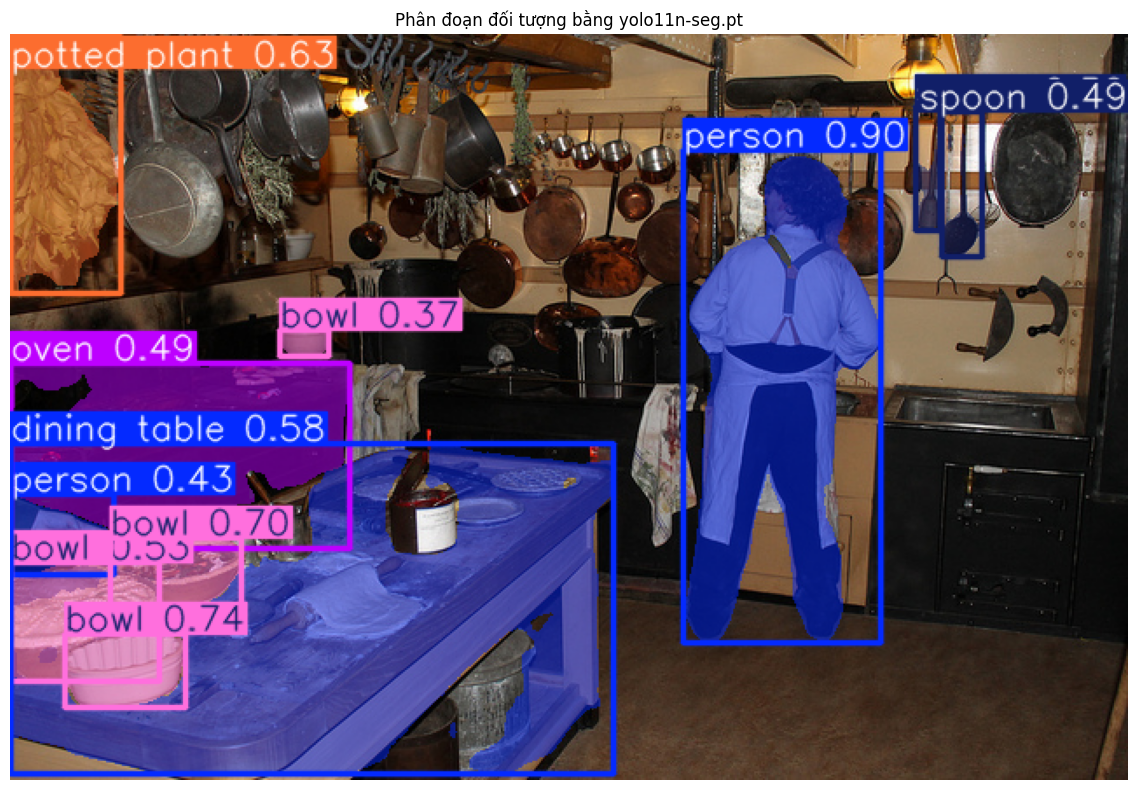

In [8]:
sample_id = "kitchen"
result = segmentation_model.predict(source=images[sample_id], conf=SEGMENTATION_SCORE_THRESHOLD, device=DEVICE, verbose=False)[0]
annotated = result.plot()[:, :, ::-1]
plt.figure(figsize=(12, 8)); plt.imshow(annotated); plt.axis("off"); plt.title(f"Phân đoạn đối tượng bằng {SEGMENTATION_MODEL_FILE}"); plt.tight_layout()
plt.savefig(VISUAL_DIR / "segmentation_prediction.png", dpi=160, bbox_inches="tight"); plt.show()
del segmentation_model
if torch.cuda.is_available(): torch.cuda.empty_cache()


## Kết thúc: validation → upload báo cáo đã làm → đóng ZIP

1. Chạy ô validation bên dưới — cần `PASS` cho JSON/PNG.
2. Chạy ô **Upload `REPORT.md`**: chọn file báo cáo **bạn đã làm xong** (điền từ `reports/REPORT_TEMPLATE.md` trên máy). Notebook không tạo mẫu trống.
3. Chạy ô đóng ZIP → tải một file → giải nén vào `report/` trên GitHub → nộp **link repo**.

Checklist nhanh:
- [ ] Mục 1 dùng sample `traffic`
- [ ] Mục 2–3 dùng sample `kitchen`
- [ ] Có ít nhất một lỗi / chỗ khó quyết định nhãn trên PNG
- [ ] Bảng mục 4 có annotator và reviewer
- [ ] Mục 5 có quy tắc an toàn dữ liệu


In [9]:
provenance_fields = {"sample_id", "coco_image_id", "image_width", "image_height", "task", "taxonomy_name", "model_file", "model_sha256", "ultralytics_version"}
required_json = {
    "classification_predictions.json": provenance_fields | {"class_id", "class_name", "rank", "score"},
    "detection_predictions.json": provenance_fields | {"class_id", "class_name", "score", "score_threshold", "coordinate_unit", "bbox_format", "bbox_xyxy", "bbox_width", "bbox_height"},
    "segmentation_predictions.json": provenance_fields | {"instance_id", "class_id", "class_name", "score", "score_threshold", "coordinate_unit", "bbox_format", "bbox_xyxy", "polygon_point_count", "polygon_xy"},
}
expected_model_by_file = {
    "classification_predictions.json": CLASSIFICATION_MODEL_FILE,
    "detection_predictions.json": DETECTION_MODEL_FILE,
    "segmentation_predictions.json": SEGMENTATION_MODEL_FILE,
}
expected_samples = set(SAMPLES)
attribution_path = OUTPUT_DIR / "IMAGE_ATTRIBUTION.md"
if not attribution_path.is_file():
    raise AssertionError("Thiếu IMAGE_ATTRIBUTION.md")
attribution_text = attribution_path.read_text(encoding="utf-8")
for metadata in SAMPLES.values():
    for required_attribution in (metadata["source_creator"], metadata["source_url"], metadata["license_url"]):
        if required_attribution not in attribution_text:
            raise AssertionError(f"Attribution thiếu: {required_attribution}")
required_png = [
    "visuals/classification_top5.png",
    "visuals/detection_predictions.png",
    "visuals/segmentation_prediction.png",
]
validated_rows = {}
for filename, expected_fields in required_json.items():
    path = OUTPUT_DIR / filename
    if not path.is_file(): raise AssertionError(f"Thiếu {path}")
    with open(path, encoding="utf-8") as file:
        rows = json.load(file)
    if not isinstance(rows, list) or not rows: raise AssertionError(f"{filename} phải là list không rỗng")
    for row_number, row in enumerate(rows, start=1):
        if not isinstance(row, dict): raise AssertionError(f"{filename} row {row_number} không phải object")
        missing_fields = expected_fields - set(row)
        if missing_fields: raise AssertionError(f"{filename} row {row_number} thiếu: {sorted(missing_fields)}")
        sample_id = row["sample_id"]
        if sample_id not in SAMPLES: raise AssertionError(f"{filename} có sample lạ: {sample_id}")
        if row.get("coco_image_id") != SAMPLES[sample_id]["coco_image_id"]:
            raise AssertionError(f"{filename} row {row_number} sai coco_image_id")
        expected_model = expected_model_by_file[filename]
        if row["model_file"] != expected_model or row.get("model_sha256") != MODEL_SHA256[expected_model]:
            raise AssertionError(f"{filename} row {row_number} sai model provenance")
        if not 0.0 <= float(row["score"]) <= 1.0:
            raise AssertionError(f"{filename} row {row_number} có score ngoài [0, 1]")
    actual_samples = {row["sample_id"] for row in rows}
    if actual_samples != expected_samples:
        raise AssertionError(f"{filename} phải có đủ sample: {sorted(expected_samples)}")
    validated_rows[filename] = rows
classification_rows = validated_rows["classification_predictions.json"]
for sample_id in expected_samples:
    ranks = sorted(row["rank"] for row in classification_rows if row["sample_id"] == sample_id)
    if ranks != [1, 2, 3, 4, 5]: raise AssertionError(f"Top-5 không hợp lệ cho {sample_id}: {ranks}")
for filename in ("detection_predictions.json", "segmentation_predictions.json"):
    for row_number, row in enumerate(validated_rows[filename], start=1):
        width, height = row["image_width"], row["image_height"]
        bbox = row["bbox_xyxy"]
        if len(bbox) != 4: raise AssertionError(f"{filename} row {row_number} bbox phải có 4 số")
        x_min, y_min, x_max, y_max = bbox
        if not (0 <= x_min < x_max <= width and 0 <= y_min < y_max <= height):
            raise AssertionError(f"{filename} row {row_number} bbox ngoài ảnh hoặc không dương")
segmentation_rows = validated_rows["segmentation_predictions.json"]
for row_number, row in enumerate(segmentation_rows, start=1):
    polygon = row["polygon_xy"]
    if len(polygon) < 3 or row.get("polygon_point_count") != len(polygon):
        raise AssertionError(f"Segmentation row {row_number} có polygon không hợp lệ")
    for point in polygon:
        if len(point) != 2 or not (0 <= point[0] <= row["image_width"] and 0 <= point[1] <= row["image_height"]):
            raise AssertionError(f"Segmentation row {row_number} có điểm polygon ngoài ảnh")
for filename in required_png:
    path = OUTPUT_DIR / filename
    if not path.is_file() or path.stat().st_size < 1000: raise AssertionError(f"Thiếu hoặc lỗi {path}")
    try:
        with Image.open(path) as image:
            image.load()
            if image.width < 100 or image.height < 100: raise AssertionError(f"Ảnh quá nhỏ: {path}")
    except Exception as error:
        raise AssertionError(f"PNG không đọc được: {path}") from error
instance_ids = [row["instance_id"] for row in segmentation_rows]
if len(instance_ids) != len(set(instance_ids)): raise AssertionError("instance_id phải duy nhất trong output")
print(f"PASS: đủ {len(required_json)} JSON, {len(required_png)} PNG, attribution và instance_id duy nhất.")
print("Evidence các tệp:", sorted(str(p) for p in OUTPUT_DIR.rglob("*") if p.is_file()))
print("Bước tiếp: điền/Save REPORT.md (nếu chưa), rồi làm theo hướng dẫn nộp link repo.")


PASS: đủ 3 JSON, 3 PNG, attribution và instance_id duy nhất.
Evidence các tệp: ['day1_lab_outputs/IMAGE_ATTRIBUTION.md', 'day1_lab_outputs/classification_predictions.json', 'day1_lab_outputs/detection_predictions.json', 'day1_lab_outputs/segmentation_predictions.json', 'day1_lab_outputs/visuals/classification_top5.png', 'day1_lab_outputs/visuals/detection_predictions.png', 'day1_lab_outputs/visuals/segmentation_prediction.png']
Bước tiếp: điền/Save REPORT.md (nếu chưa), rồi làm theo hướng dẫn nộp link repo.


## Upload `REPORT.md` đã làm xong

Chỉ upload báo cáo **bạn đã viết xong**. Không dùng file mẫu trống.

Trên máy: mở `reports/REPORT_TEMPLATE.md` trong repo → điền → lưu thành `REPORT.md` → chạy ô dưới và chọn file đó.


In [ ]:
# Upload REPORT.md đã làm xong (không tự sinh mẫu trống).
REPORT_PATH = Path("REPORT.md")
EMPTY_TEMPLATE_SHA256 = REPORT_TEMPLATE_ASSET["sha256"]

try:
    from google.colab import files as colab_files
except ImportError:
    colab_files = None

if colab_files is not None:
    print("Chọn file REPORT.md ĐÃ ĐIỀN trên máy (không chọn reports/REPORT_TEMPLATE.md).")
    uploaded = colab_files.upload()
    if not uploaded:
        raise FileNotFoundError("Bạn chưa chọn file nào. Hãy chạy lại ô và upload REPORT.md đã làm.")

    # Colab có thể đổi tên thành "REPORT (1).md" nếu REPORT.md đã tồn tại.
    # Lấy file .md mới nhất trong batch upload (không ưu tiên tên cũ trên disk).
    md_items = [(name, data) for name, data in uploaded.items() if str(name).lower().endswith(".md")]
    if not md_items:
        raise ValueError("File upload phải là .md (khuyến nghị tên REPORT.md đã điền).")
    chosen_name, payload = max(md_items, key=lambda item: len(item[1]))
    REPORT_PATH.write_bytes(payload)
    print(f"Đã nhận upload: {chosen_name} ({len(payload)} bytes) → lưu thành {REPORT_PATH.name}")
else:
    if not REPORT_PATH.is_file():
        raise FileNotFoundError(
            "Không phải Colab và chưa có REPORT.md trong thư mục chạy. "
            "Hãy đặt sẵn REPORT.md đã điền cạnh notebook."
        )
    print(f"SKIP widget upload: dùng sẵn {REPORT_PATH.resolve()}")

if not REPORT_PATH.is_file():
    raise FileNotFoundError("Thiếu REPORT.md sau bước upload.")

report_bytes = REPORT_PATH.read_bytes()
report_sha256 = sha256_file(REPORT_PATH)
print(f"Kích thước file: {len(report_bytes)} bytes; sha256={report_sha256[:12]}…")

if report_sha256 == EMPTY_TEMPLATE_SHA256:
    raise ValueError(
        "File vừa upload vẫn là MẪU TRỐNG (trùng checksum reports/REPORT_TEMPLATE.md). "
        "Hãy upload đúng file REPORT.md đã trả lời (ở gốc repo, thường > 7KB), "
        "không upload reports/REPORT_TEMPLATE.md."
    )

print("PASS: REPORT.md đã upload và không còn là mẫu trống.")


Chọn file REPORT.md ĐÃ ĐIỀN trên máy (không chọn reports/REPORT_TEMPLATE.md).


## Đóng ZIP và đưa lên GitHub

Ô dưới kiểm tra lại `REPORT.md` (vừa upload) + `day1_lab_outputs/`, rồi tải về **một** file `day1_report_for_upload.zip`.

Giải nén → GitHub repo → `report/` → **Upload files** → Commit → nộp **link repo** trên LMS. Không commit/nộp ZIP.


In [ ]:
# Kiểm tra bài làm rồi đóng một ZIP để tải về (trung chuyển lên GitHub).
import zipfile
from shutil import copy2, copytree, rmtree

if not REPORT_PATH.is_file():
    raise FileNotFoundError("Thiếu REPORT.md. Hãy chạy ô Upload REPORT.md phía trên trước.")

report_sha256 = sha256_file(REPORT_PATH)
if report_sha256 == REPORT_TEMPLATE_ASSET["sha256"]:
    raise ValueError(
        "REPORT.md chưa được điền (vẫn trùng mẫu trống). "
        "Hãy upload lại REPORT.md đã điền (không phải mẫu trống)."
    )

required_upload = [
    REPORT_PATH.name,
    f"{OUTPUT_DIR.name}/IMAGE_ATTRIBUTION.md",
    *(f"{OUTPUT_DIR.name}/{filename}" for filename in required_json),
    *(f"{OUTPUT_DIR.name}/{filename}" for filename in required_png),
]
missing = [relative for relative in required_upload if not Path(relative).is_file()]
if missing:
    raise FileNotFoundError(f"Thiếu file cần có trong bài nộp: {missing}")

# Staging đúng cấu trúc sẽ upload vào report/ trên GitHub
staging_dir = Path("day1_report_staging")
if staging_dir.exists():
    rmtree(staging_dir)
staging_dir.mkdir(parents=True)
copy2(REPORT_PATH, staging_dir / "REPORT.md")
copytree(OUTPUT_DIR, staging_dir / OUTPUT_DIR.name)

expected_files = set(required_upload)
actual_files = {
    path.relative_to(staging_dir).as_posix()
    for path in staging_dir.rglob("*")
    if path.is_file()
}
if actual_files != expected_files:
    raise AssertionError(
        "Cấu trúc staging sai; "
        f"thieu={sorted(expected_files - actual_files)}; "
        f"thua={sorted(actual_files - expected_files)}"
    )

TRANSFER_ZIP = Path("day1_report_for_upload.zip")
if TRANSFER_ZIP.exists():
    TRANSFER_ZIP.unlink()
with zipfile.ZipFile(TRANSFER_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for path in sorted(staging_dir.rglob("*")):
        if path.is_file():
            archive.write(path, arcname=path.relative_to(staging_dir).as_posix())
with zipfile.ZipFile(TRANSFER_ZIP) as archive:
    zipped = {item.filename for item in archive.infolist() if not item.is_dir()}
if zipped != expected_files:
    raise AssertionError(
        "ZIP sai cấu trúc; "
        f"thieu={sorted(expected_files - zipped)}; "
        f"thua={sorted(zipped - expected_files)}"
    )

rmtree(staging_dir)

print("PASS: đã đóng ZIP từ REPORT.md đã upload + day1_lab_outputs/")
print("Giải nén ZIP sẽ thấy:")
for relative in sorted(expected_files):
    print(f"  {relative}")
print("Tiếp: giải nén ZIP → Upload vào thư mục report/ trên GitHub → Commit → nộp link repo.")

try:
    from google.colab import files as colab_files
except ImportError:
    colab_files = None
if colab_files is not None:
    colab_files.download(str(TRANSFER_ZIP))
    print("Colab đang tải day1_report_for_upload.zip về máy bạn.")
else:
    print(f"SKIP auto-download: không phải Colab — lấy file tại {TRANSFER_ZIP.resolve()}")
